# Deep Learning, Phase 1, Day 3: PyTorch Basics, Re-implementation, SGD vs Adam


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
sns.set_theme(style='whitegrid')
print('PyTorch', torch.__version__, '| GPU available:', torch.cuda.is_available())

PyTorch 2.11.0+cpu | GPU available: False


## 1. Tensors
A **tensor** is PyTorch's array. It works like a NumPy array, but it can track gradients and run on a GPU. (This small project runs fine on the CPU. From Phase 2, CNNs, we will switch the GPU on in Colab: Runtime > Change runtime type.)

In [2]:
a = torch.tensor([[1., 2.], [3., 4.]])
b = torch.ones(2, 2)
print(a + b)                      # element-wise
print(a @ b)                      # matrix multiplication, same as NumPy
print('shape:', a.shape, '| dtype:', a.dtype)
n = a.numpy(); print('to NumPy:', type(n)); print('from NumPy:', torch.from_numpy(np.array([1., 2.])))

tensor([[2., 3.],
        [4., 5.]])
tensor([[3., 3.],
        [7., 7.]])
shape: torch.Size([2, 2]) | dtype: torch.float32
to NumPy: <class 'numpy.ndarray'>
from NumPy: tensor([1., 2.], dtype=torch.float64)


## 2. Autograd: gradients for free
If a tensor is created with `requires_grad=True`, PyTorch records every operation on it. `loss.backward()` then computes **all** the gradients with the chain rule, which is exactly what we coded by hand on Day 2. Check it on the same small example (answer on Day 2 was -0.28926):

In [3]:
x = torch.tensor(1.5); y = torch.tensor(1.0)
w = torch.tensor(0.4, requires_grad=True); b = torch.tensor(-0.2, requires_grad=True)

p = torch.sigmoid(w * x + b)
loss = (p - y) ** 2
loss.backward()                   # backpropagation
print('dL/dw from autograd:', w.grad.item(), '(Day 2 chain rule: -0.28926)')
print('dL/db from autograd:', b.grad.item())

dL/dw from autograd: -0.28925880789756775 (Day 2 chain rule: -0.28926)
dL/db from autograd: -0.19283920526504517


Gradients **accumulate** in `.grad` each time you call `backward()`, so in a training loop we must reset them with `optimizer.zero_grad()` every step.

## 3. Building a model with `nn.Module`
`nn.Linear(n_in, n_out)` is one layer (weights + bias). `nn.Sequential` chains layers and activations. Our Day 2 network, input 2 -> hidden 8 (ReLU) -> output 1:

The model outputs **raw scores (logits)**, with no sigmoid at the end. The loss `BCEWithLogitsLoss` applies the sigmoid inside, in a numerically safer way. (To get probabilities later we apply `torch.sigmoid` ourselves.)

In [4]:
def make_model(n_hidden=8, seed=0):
    torch.manual_seed(seed)           # same seed = same starting weights
    return nn.Sequential(nn.Linear(2, n_hidden), nn.ReLU(), nn.Linear(n_hidden, 1))

model = make_model()
print(model)
for name, p_ in model.named_parameters(): print(f'{name:10s} shape {tuple(p_.shape)}')
print('Total parameters:', sum(p_.numel() for p_ in model.parameters()), '(Day 1 formula said 33)')

Sequential(
  (0): Linear(in_features=2, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=1, bias=True)
)
0.weight   shape (8, 2)
0.bias     shape (8,)
2.weight   shape (1, 8)
2.bias     shape (1,)
Total parameters: 33 (Day 1 formula said 33)


Note: PyTorch stores the weight of `nn.Linear(2, 8)` with shape **(8, 2)**, which is the transpose of our NumPy `W1` (2, 8). It computes `X @ W.T + b`, the same thing.

A custom model class does the same, and is the form you will see in most code. Equivalent version:

In [5]:
class MLP(nn.Module):
    def __init__(self, n_in=2, n_hidden=8):
        super().__init__()
        self.fc1 = nn.Linear(n_in, n_hidden)
        self.fc2 = nn.Linear(n_hidden, 1)
        self.act = nn.ReLU()
    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))

print(MLP())

MLP(
  (fc1): Linear(in_features=2, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=1, bias=True)
  (act): ReLU()
)


## 4. Data and `DataLoader`
Same two-moons data and split as Day 2, converted to tensors. A `DataLoader` hands the data to the model in **mini-batches** (e.g. 32 samples) and reshuffles every epoch. Mini-batches give many cheaper, noisier updates per epoch instead of one big one.

In [6]:
X, y = make_moons(n_samples=600, noise=0.25, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
Xtr, Xte = torch.tensor(X_train, dtype=torch.float32), torch.tensor(X_test, dtype=torch.float32)
ytr, yte = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1), torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)
print('Train:', Xtr.shape, ytr.shape, '| Test:', Xte.shape)

loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=32, shuffle=True)
xb, yb = next(iter(loader)); print('One mini-batch:', xb.shape, yb.shape, '| batches per epoch:', len(loader))

Train: torch.Size([450, 2]) torch.Size([450, 1]) | Test: torch.Size([150, 2])
One mini-batch: torch.Size([32, 2]) torch.Size([32, 1]) | batches per epoch: 15


## 5. The training loop
Every PyTorch training loop has the same five lines inside:
1. `optimizer.zero_grad()`  (reset old gradients)
2. `out = model(xb)`  (forward pass)
3. `loss = loss_fn(out, yb)`
4. `loss.backward()`  (backpropagation)
5. `optimizer.step()`  (update the weights)

After each epoch we measure the full train and test loss and accuracy with `model.eval()` and `torch.no_grad()` (no gradient tracking when we only predict).

In [7]:
loss_fn = nn.BCEWithLogitsLoss()

def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        return loss_fn(logits, y).item(), ((logits > 0).float() == y).float().mean().item()   # logit > 0  <=>  probability > 0.5

def train(model, optimizer, epochs, batch_size=None):
    dl = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch_size or len(Xtr), shuffle=batch_size is not None)
    hist = {'loss': [], 'acc': [], 'val_loss': [], 'val_acc': []}
    for ep in range(epochs):
        model.train()
        for xb, yb in dl:
            optimizer.zero_grad()                 # 1
            loss = loss_fn(model(xb), yb)         # 2, 3
            loss.backward()                       # 4
            optimizer.step()                      # 5
        l, a = evaluate(model, Xtr, ytr); vl, va = evaluate(model, Xte, yte)
        for k, v in zip(hist, (l, a, vl, va)): hist[k].append(v)
    return hist

## 6. Compare with yesterday's NumPy network
Same setup as Day 2: full-batch gradient descent (all samples at once), SGD with learning rate 0.1, 1500 epochs. The starting weights differ (different random initialisation), so the numbers will be similar but not identical.

In [8]:
m_sgd_full = make_model()
h_full = train(m_sgd_full, torch.optim.SGD(m_sgd_full.parameters(), lr=0.1), epochs=1500, batch_size=None)
print(f"PyTorch full-batch SGD: train acc {h_full['acc'][-1]:.3f}, test acc {h_full['val_acc'][-1]:.3f}, final loss {h_full['loss'][-1]:.3f}")
print('Day 2 NumPy network   : train acc 0.887, test acc 0.880, final loss 0.287   (from my run, yours may differ slightly)')

PyTorch full-batch SGD: train acc 0.904, test acc 0.893, final loss 0.268
Day 2 NumPy network   : train acc 0.887, test acc 0.880, final loss 0.287   (from my run, yours may differ slightly)


## 7. Optimizers: SGD vs Adam
- **SGD**: `w = w - lr x gradient`. Simple, but sensitive to the learning rate.
- **SGD with momentum**: keeps a running average of past gradients, like a rolling ball, which smooths and speeds up the descent.
- **Adam**: momentum **plus** a separate, automatically adapted step size for every weight. Usually trains faster with little tuning, so it is the common default.

Same model, same starting weights, same mini-batches (size 32), 100 epochs:

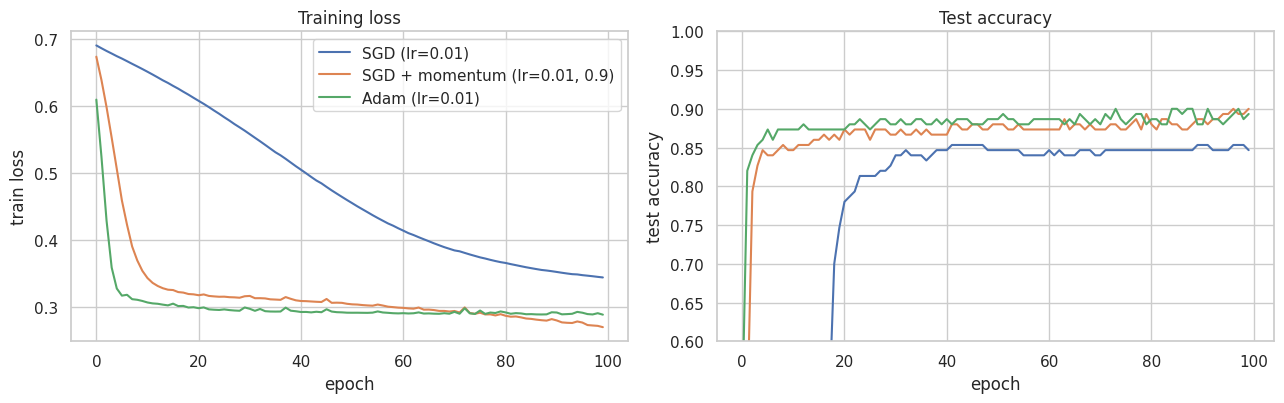

,final train loss,final test acc,epochs to reach loss < 0.4
SGD (lr=0.01),0.344,0.847,66.0
"SGD + momentum (lr=0.01, 0.9)",0.269,0.900,8.0
Adam (lr=0.01),0.288,0.893,4.0


In [9]:
configs = {'SGD (lr=0.01)': lambda p_: torch.optim.SGD(p_, lr=0.01),
           'SGD + momentum (lr=0.01, 0.9)': lambda p_: torch.optim.SGD(p_, lr=0.01, momentum=0.9),
           'Adam (lr=0.01)': lambda p_: torch.optim.Adam(p_, lr=0.01)}
runs, models = {}, {}
for name, make_opt in configs.items():
    torch.manual_seed(1)                                   # same mini-batch order for every optimizer
    m = make_model(); runs[name] = train(m, make_opt(m.parameters()), epochs=100, batch_size=32); models[name] = m

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for name, h in runs.items():
    ax[0].plot(h['loss'], label=name); ax[1].plot(h['val_acc'], label=name)
ax[0].set(xlabel='epoch', ylabel='train loss', title='Training loss'); ax[1].set(xlabel='epoch', ylabel='test accuracy', title='Test accuracy', ylim=(0.6, 1.0)); ax[0].legend()
plt.tight_layout(); plt.show()
pd.DataFrame({n: {'final train loss': h['loss'][-1], 'final test acc': h['val_acc'][-1],
                  'epochs to reach loss < 0.4': next((i + 1 for i, v in enumerate(h['loss']) if v < 0.4), None)} for n, h in runs.items()}).T.round(3)

## 8. Decision boundary and saving the model

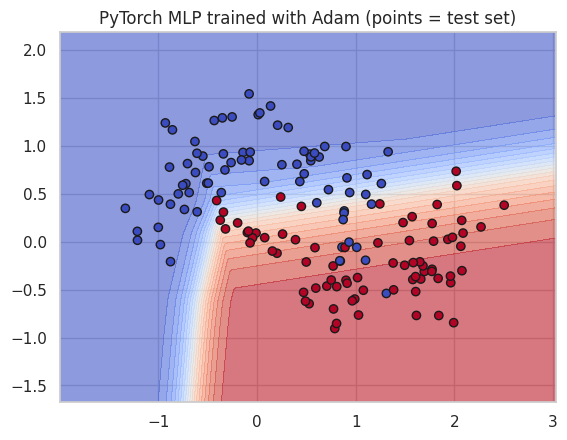

Reloaded model test accuracy: 0.893


In [10]:
best = models['Adam (lr=0.01)']
xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - .5, X[:, 0].max() + .5, 250), np.linspace(X[:, 1].min() - .5, X[:, 1].max() + .5, 250))
grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
best.eval()
with torch.no_grad(): zz = torch.sigmoid(best(grid)).numpy().reshape(xx.shape)
plt.contourf(xx, yy, zz, levels=20, cmap='coolwarm', alpha=.6); plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='coolwarm', edgecolor='k')
plt.title('PyTorch MLP trained with Adam (points = test set)'); plt.show()

torch.save(best.state_dict(), 'moons_mlp.pt')                 # save only the learned parameters
reloaded = make_model(); reloaded.load_state_dict(torch.load('moons_mlp.pt'))
print('Reloaded model test accuracy:', round(evaluate(reloaded, Xte, yte)[1], 3))